# KernelSynth corpus | Signed AR coefficients across orders

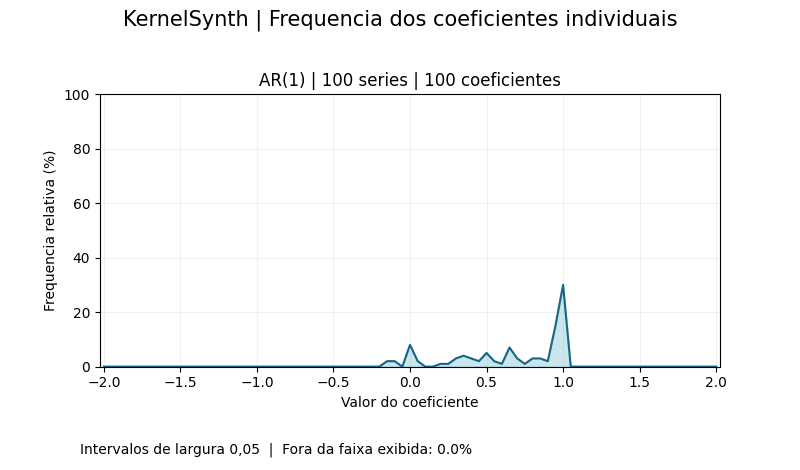

In [1]:
from pathlib import Path
import hashlib,json,platform,subprocess
import requests,numpy as np,pyarrow.parquet as pq,matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits
from PIL import Image
from io import BytesIO
root=next(x for x in (Path.cwd(),*Path.cwd().parents) if (x/'pyproject.toml').exists())
url='https://huggingface.co/datasets/autogluon/chronos_datasets/resolve/main/training_corpus/kernel_synth_1m/train-00000-of-00020.parquet'
path=root/'data/raw/kernelsynth-shard0.parquet'
if not path.exists():
    path.parent.mkdir(parents=True,exist_ok=True)
    with requests.get(url,stream=True,timeout=120) as response:
        response.raise_for_status()
        with path.open('wb') as out:
            for chunk in response.iter_content(1048576):out.write(chunk)
table=pq.read_table(path,columns=['target','id'])
seed=20260930
indices=np.random.default_rng(seed).choice(len(table),100,replace=False)
sample=table.take(indices).to_pylist()
orders=[1,2,3,4,6,8,12,16,24,32,64,128,256]
weights={p:[] for p in orders}
with threadpool_limits(limits=1):
    for row in sample:
        y=np.asarray(row['target']); assert len(y)==1024 and np.isfinite(y).all()
        y=(y-y.mean())/(y.std()+1e-12)
        for p in orders:
            windows=np.lib.stride_tricks.sliding_window_view(y,p+1)
            X=np.column_stack((np.ones(len(windows)),windows[:,:-1][:,::-1]))
            penalty=np.eye(p+1)*1e-5;penalty[0,0]=0
            weights[p].append(np.linalg.solve(X.T@X+penalty,X.T@windows[:,-1])[1:])
frames=[];metrics=[];edges=np.linspace(-2.025,2.025,82)
for p in orders:
    a=np.asarray(weights[p]); assert a.shape==(100,p) and np.isfinite(a).all()
    h=100*np.histogram(a,bins=edges)[0]/a.size
    metrics.append(dict(order=p,median_mean_abs=float(np.median(np.abs(a).mean(axis=1))),outside_pct=float(100-h.sum())))
    fig,ax=plt.subplots(figsize=(8,4.7),dpi=100);fig.subplots_adjust(bottom=.22,top=.80)
    fig.suptitle('KernelSynth | Frequencia dos coeficientes individuais',fontsize=15)
    ax.set_title(f'AR({p}) | 100 series | {a.size} coeficientes')
    mid=(edges[:-1]+edges[1:])/2;ax.plot(mid,h,color='#166686');ax.fill_between(mid,0,h,color='#66bacc',alpha=.35)
    ax.set(xlim=(edges[0],edges[-1]),ylim=(0,100),xlabel='Valor do coeficiente',ylabel='Frequencia relativa (%)');ax.grid(alpha=.18)
    fig.text(.1,.035,f'Intervalos de largura 0,05  |  Fora da faixa exibida: {max(0,100-h.sum()):.1f}%')
    b=BytesIO();fig.savefig(b,format='png');b.seek(0);frames.append(Image.open(b).convert('RGB'));plt.close(fig)
gif=root/'outputs/kernelsynth_corpus_100_frequencia.gif';gif.parent.mkdir(exist_ok=True)
frames[0].save(gif,save_all=True,append_images=frames[1:],duration=1200,loop=0)
assert Image.open(gif).n_frames==len(orders)
from IPython.display import Image as InlineImage, display
display(InlineImage(filename=str(gif)))


In [2]:
# COMPLETE EXPERIMENT RECORD
slopes=np.polyfit(np.log(orders),np.log([np.abs(weights[p]).mean(axis=1) for p in orders]),1)[0]
record=dict(question='How does the distribution of signed fitted lag coefficients vary with AR order?',hypothesis='Typical magnitude declines as lag count increases.',dataset=url,sha256=hashlib.sha256(path.read_bytes()).hexdigest(),seed=seed,indices=indices.tolist(),ids=[row['id'] for row in sample],configuration=dict(orders=orders,length=1024,ridge=1e-5,intercept='unpenalized, excluded',standardization='per series',sampling='100 random rows without replacement from shard zero, paired across orders',bin_edges=edges.tolist(),denominator='all 100*p coefficients'),metrics=metrics,negative_slopes=int(sum(slopes<0)),median_loglog_slope=float(np.median(slopes)),summary=f'{sum(slopes<0)}/100 negative fitted slopes. Median exponent {np.median(slopes):.3f}. One shard; one realization per model.',python=platform.python_version(),numpy=np.__version__,git=subprocess.check_output(['git','rev-parse','HEAD'],cwd=root,text=True).strip(),reproduction='python -m jupyter nbconvert --execute --to notebook --inplace experiments/autoregressive_process_coverage/kernelsynth_corpus_100/01_ar_distributions.ipynb')
print(json.dumps(record))


{"question": "How does the distribution of signed fitted lag coefficients vary with AR order?", "hypothesis": "Typical magnitude declines as lag count increases.", "dataset": "https://huggingface.co/datasets/autogluon/chronos_datasets/resolve/main/training_corpus/kernel_synth_1m/train-00000-of-00020.parquet", "sha256": "de21af74a3c6a30d581896085ac56afce0b692bf1ce66c7f514e88a837d077f4", "seed": 20260930, "indices": [41757, 34263, 7587, 29123, 16452, 33298, 37794, 40586, 41852, 1312, 25464, 45328, 8149, 4017, 35033, 10023, 25051, 34772, 6769, 546, 9127, 24077, 19908, 47486, 30935, 23263, 21330, 15121, 26508, 19338, 28992, 25106, 24099, 44234, 39595, 40111, 27292, 8739, 7848, 9717, 5255, 45042, 4393, 11772, 30453, 41577, 3756, 27843, 23368, 39115, 29617, 10237, 32273, 38769, 43213, 30517, 29599, 38259, 49269, 18172, 37203, 9525, 1501, 47977, 49080, 37011, 309, 14072, 20827, 37313, 26950, 44914, 7627, 12538, 28748, 17309, 24096, 7272, 24004, 23403, 18294, 12421, 34542, 38058, 22645, 34873,